In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from glob import glob
from os.path import join
from multiprocessing import Pool
import pyarrow.parquet as pq
from skmob.core.trajectorydataframe import TrajDataFrame
from skmob.measures import individual

In [2]:
base_path = ""
key_file = ""
daily_files = sorted(glob(join(base_path, "veraset*")))

In [3]:
def get_row_groups(row_group, files):
    """ Read a specific row group across all files. """
    
    return pd.concat([pq.ParquetFile(f, metadata=m).read_row_group(row_group).to_pandas() for f, m in zip(files, meta)]) 

def get_row_group_trajectories(row_group, files):
    """ Read the row group from all files and return a skmobility Trajectory DataFrame """
    df = get_row_groups(row_group, files)
    tdf = TrajDataFrame(df.reset_index(), latitude='latitude', longitude='longitude', datetime='datetime', user_id='caid')
    
    return tdf

def get_home_location(row_group, files):
    """ Read the row group from all files and return the home location of each user. """

    tdf = get_row_group_trajectories(row_group, files)
    
    return individual.home_location(tdf, show_progress=False)

In [4]:
meta = [pq.ParquetFile(x).metadata for x in daily_files]
row_groups = np.arange(0, 1000) #57431
files = [daily_files] * len(row_groups)
args = [(rg, f) for rg, f in zip(row_groups, files)]

In [5]:
%%time
with Pool(processes=8) as pool:
    data = pd.concat(pool.starmap(get_row_groups, args))

CPU times: user 8.79 s, sys: 9.62 s, total: 18.4 s
Wall time: 20.9 s


In [6]:
data['horizontal_accuracy'].max()

2000

<Axes: xlabel='horizontal_accuracy', ylabel='Count'>

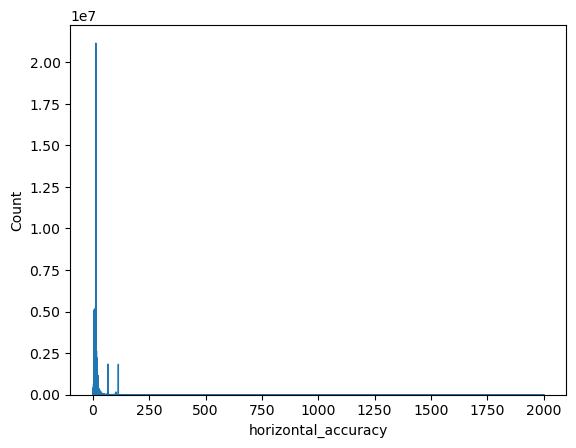

In [23]:
sns.histplot(data=data, x="horizontal_accuracy", element="poly")

<Axes: xlabel='horizontal_accuracy', ylabel='Count'>

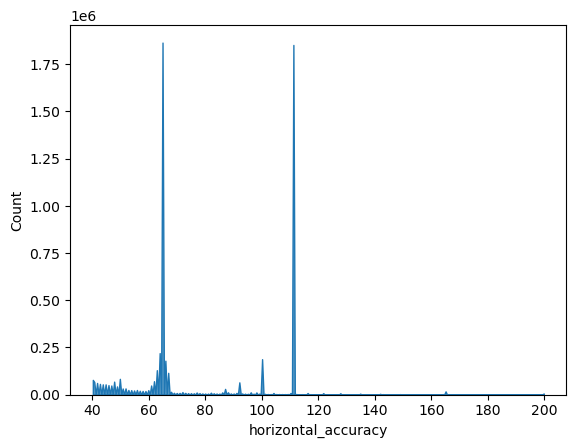

In [33]:
sns.histplot(data=data, x="horizontal_accuracy", element="poly", binrange=[40, 200])

<Axes: xlabel='horizontal_accuracy', ylabel='Count'>

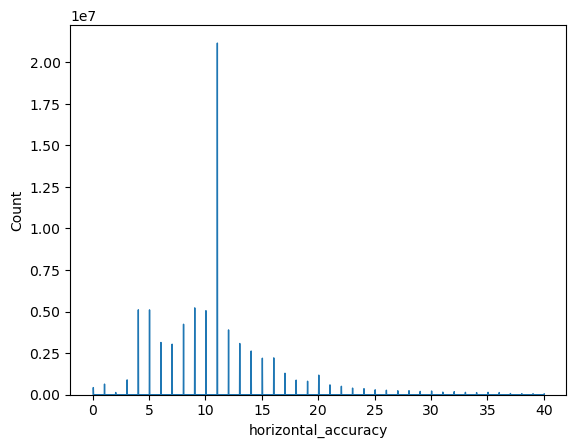

In [32]:
sns.histplot(data=data, x="horizontal_accuracy", element="poly", binrange=[0, 40])

<Axes: xlabel='horizontal_accuracy', ylabel='Count'>

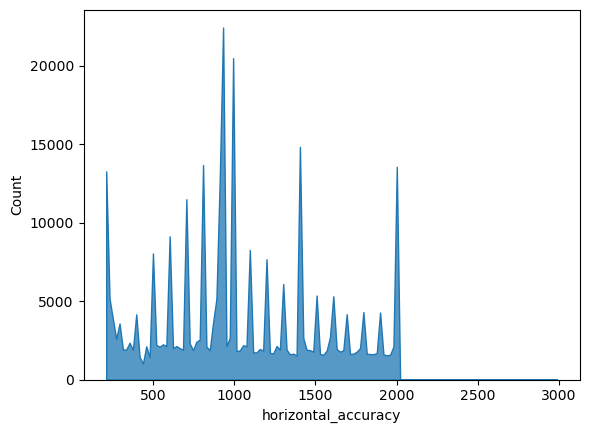

In [34]:
sns.histplot(data=data, x="horizontal_accuracy", element="poly", binrange=[200, 3000])